# TP01 — Génération et diffusion 1D
Réalisation intégrée à FraudLab, d’après le notebook TP01 étudiant fourni (ECE).
Données entièrement synthétiques ; les résultats ne décrivent pas une banque réelle.
Les exercices conservent les seeds, distributions et contrôles du sujet. Les explications ci-dessous sont celles de notre réalisation, pas une copie du support.
Exécution : `python scripts/execute_course_notebooks.py`. Figures et preuve dans `experiments/tp01/`.
Les contributions humaines restent à décider ; réalisation assistée par Codex.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
SEED = 20261102
print('NumPy', np.__version__, '| seed', SEED)
def verifier(numero, condition, commentaire=''):
    assert bool(condition), f'{numero} : {commentaire}'
    print(f'{numero} : vérification réussie. {commentaire}')


NumPy 2.5.5 | seed 20261102


N = 4000 moyenne = -0.63 écart-type = 2.155


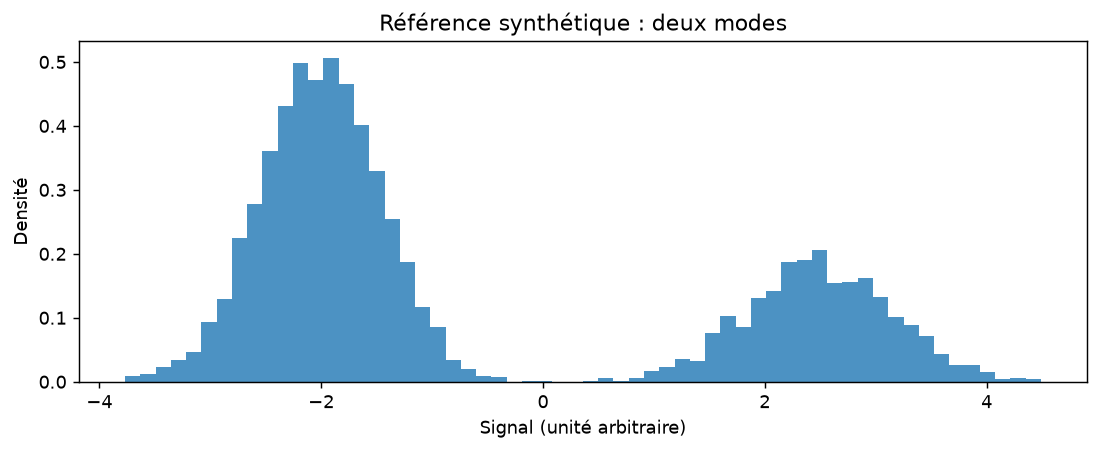

In [2]:
rng_ref = np.random.default_rng(SEED)
labels_ref = rng_ref.choice(2, size=4000, p=[.70,.30])
x_ref = np.where(labels_ref == 0, rng_ref.normal(-2,.55,4000), rng_ref.normal(2.5,.65,4000))
fig, ax = plt.subplots(figsize=(10,3.4))
ax.hist(x_ref, bins=60, density=True, alpha=.8)
ax.set(xlabel='Signal (unité arbitraire)', ylabel='Densité', title='Référence synthétique : deux modes')
plt.show()
print('N =',len(x_ref),'moyenne =',round(x_ref.mean(),4),'écart-type =',round(x_ref.std(),4))


## E1 — Loi gaussienne et reproductibilité

In [3]:
def generer_gaussienne(n, mu, sigma, seed):
    if int(n) != n or n < 0 or sigma < 0:
        raise ValueError('n entier non négatif et sigma non négatif requis')
    return np.random.default_rng(seed).normal(mu, sigma, int(n))
e1 = generer_gaussienne(4000, 10, 2, SEED)
print('Moyenne :',e1.mean(),'écart-type :',e1.std())
verifier('E1',e1.shape == (4000,) and abs(e1.mean()-10)<.2 and abs(e1.std()-2)<.2)
assert np.array_equal(e1, generer_gaussienne(4000,10,2,SEED))


Moyenne : 9.98765526628242 écart-type : 2.016487255621931
E1 : vérification réussie. 


Une seed identique reproduit les tirages. La moyenne et l’écart-type empiriques fluctuent autour des paramètres ; une seule gaussienne ne représente pas nécessairement deux populations.

## E2 — Mélange de deux populations 70/30

Part x<0 : 0.70625 part x>1.2 : 0.285
E2 : vérification réussie. 


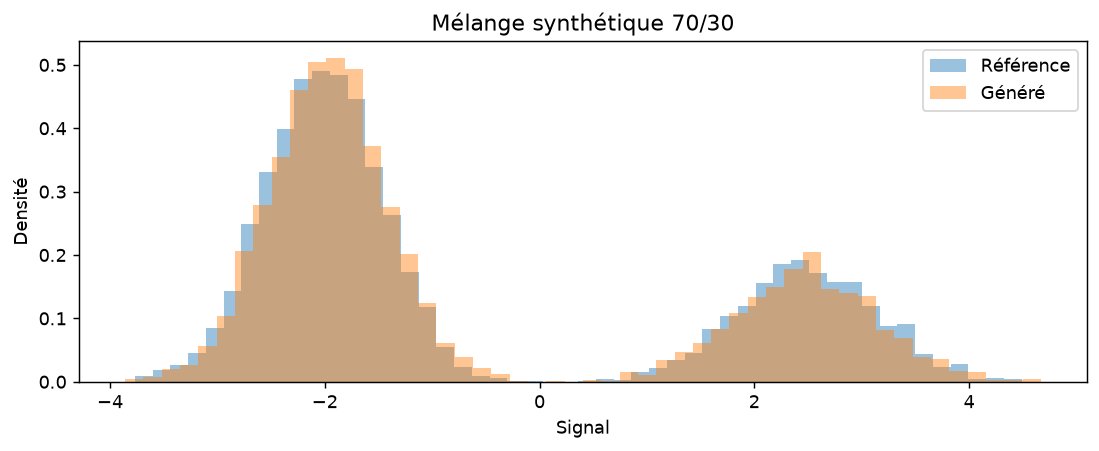

In [4]:
def generer_melange(n, seed):
    rng = np.random.default_rng(seed)
    labels = rng.choice([0,1], size=n, p=[.7,.3])
    return np.where(labels == 0, rng.normal(-2,.55,n), rng.normal(2.5,.65,n))
e2 = generer_melange(4000,SEED+1)
fig,ax=plt.subplots(figsize=(10,3.4))
ax.hist(x_ref,50,alpha=.45,density=True,label='Référence')
ax.hist(e2,50,alpha=.45,density=True,label='Généré')
ax.legend();ax.set(title='Mélange synthétique 70/30',xlabel='Signal',ylabel='Densité');plt.show()
print('Part x<0 :',np.mean(e2<0),'part x>1.2 :',np.mean(e2>1.2))
verifier('E2',len(e2)==4000 and .62<np.mean(e2<0)<.78 and .20<np.mean(e2>1.2)<.38)


Le mélange couvre deux zones, contrairement à la gaussienne unique. La proportion au-delà d’un seuil est une approximation de la population latente, car les distributions ont des queues.

## E3 — Couverture et baseline à un seul mode

Référence : {'A': 0.67425, 'B': 0.29975} baseline : {'A': 0.96125, 'B': 0.0} mélange : {'A': 0.6785, 'B': 0.285}
E3 : vérification réussie. 


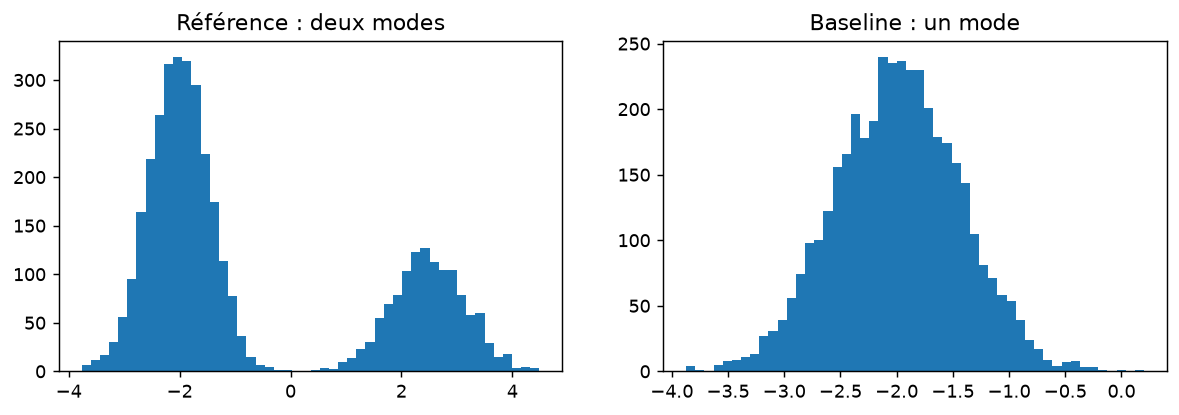

In [5]:
baseline=np.random.default_rng(SEED+3).normal(-2,.55,4000)
def couverture_modes(x):
    x=np.asarray(x)
    return {'A':float(np.mean(x < -1)), 'B':float(np.mean(x > 1.2))}
c_ref= couverture_modes(x_ref);c_bad=couverture_modes(baseline);c_gen=couverture_modes(e2)
print('Référence :',c_ref,'baseline :',c_bad,'mélange :',c_gen)
fig,axs=plt.subplots(1,2,figsize=(11,3.3))
axs[0].hist(x_ref,50);axs[0].set_title('Référence : deux modes')
axs[1].hist(baseline,50);axs[1].set_title('Baseline : un mode');plt.show()
verifier('E3',.20<c_ref['B']<.4 and c_bad['B']<.02)


Une bonne fidélité locale autour du mode A ne suffit pas : la baseline oublie le mode B. Il faut mesurer la couverture et non seulement la moyenne.

## E4 — Bruitage forward

E4 : vérification réussie. 
alpha_bar 1.0 écart-type 2.155 SNR infini
alpha_bar 0.8 écart-type 1.9769 SNR 4.000000000000001
alpha_bar 0.4 écart-type 1.5639 SNR 0.6666666666666667
alpha_bar 0.05 écart-type 1.0821 SNR 0.052631578947368425


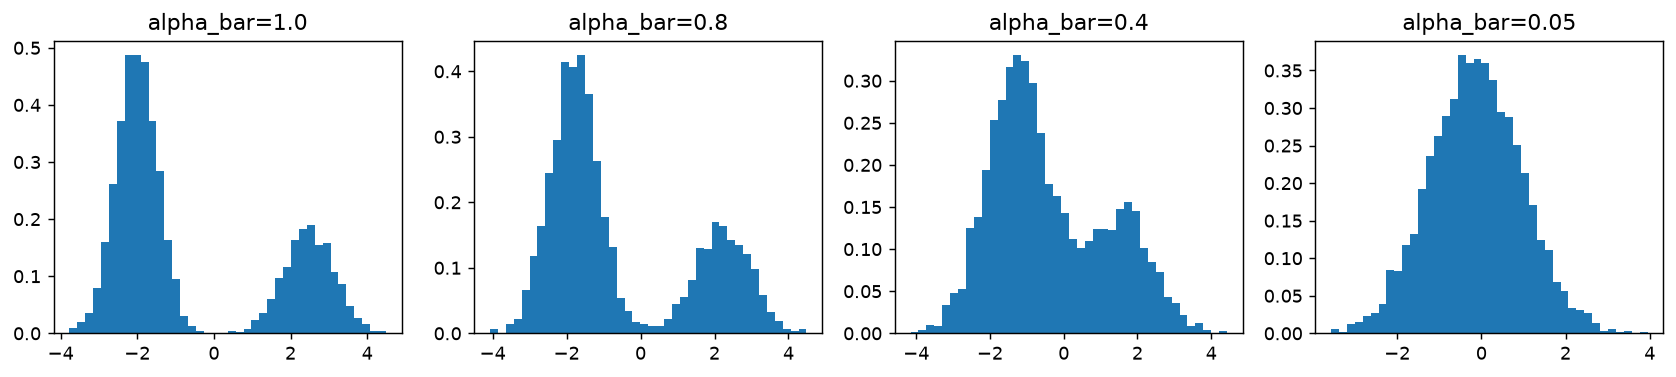

In [6]:
def diffusion_forward(x0, alpha_bar, seed):
    if not 0 <= alpha_bar <= 1:
        raise ValueError('alpha_bar doit appartenir à [0,1]')
    x0=np.asarray(x0)
    eps=np.random.default_rng(seed).normal(size=x0.shape)
    return np.sqrt(alpha_bar)*x0 + np.sqrt(1-alpha_bar)*eps
alphas=[1.,.8,.4,.05]
noisy=[diffusion_forward(x_ref,a,SEED+10) for a in alphas]
fig,axs=plt.subplots(1,4,figsize=(13,3))
for ax,a,v in zip(axs,alphas,noisy):
    ax.hist(v,40,density=True);ax.set_title(f'alpha_bar={a}')
plt.tight_layout();plt.show()
verifier('E4',all(v.shape==x_ref.shape for v in noisy) and np.allclose(noisy[0],x_ref) and .7<noisy[-1].std()<1.3)
for a,v in zip(alphas,noisy):print('alpha_bar',a,'écart-type',round(v.std(),4),'SNR',a/(1-a) if a<1 else 'infini')
assert np.array_equal(diffusion_forward(x_ref,0,SEED+10),np.random.default_rng(SEED+10).normal(size=x_ref.shape))


Le signal disparaît progressivement quand alpha_bar diminue. À 1, on retrouve x0 ; à 0, seulement le bruit. Le forward ne contient aucun réseau entraîné et ne constitue pas à lui seul un générateur appris.

## E5 — Décision et cinq réponses
1. La référence présente deux modes : une majorité près de −2 et une minorité près de 2,5. Une moyenne unique masque ces deux populations.
2. Les proportions exactes de couverture sont affichées en E3 : le mode B approche 30 % dans la référence et presque 0 % dans la baseline. Celle-ci ne convient donc pas à l’enrichissement des cas rares.
3. Le forward est une corruption gaussienne fixée. Il ne sait ni apprendre la distribution ni inverser le processus ; un débruiteur et un sampler inverse doivent être appris/implémentés séparément.
4. Le protocole minimal sépare train, validation et test indépendant, compare baseline et candidat sur les mêmes entrées, mesure fidélité, diversité et utilité du détecteur, et répète les seeds. Une validation sur données réelles autorisées est indispensable avant usage métier.
5. Recommandation : ne pas retenir la baseline à un mode pour augmenter un détecteur de défauts rares. Conserver le mélange comme baseline pédagogique, contrôler chaque segment et vérifier l’utilité sur un test réel. Nos histogrammes synthétiques ne démontrent aucun bénéfice bancaire.

## Lien avec le projet final
Le DDPM bancaire de `src/run_experiment.py` apprend le reverse en 29 dimensions. Le contrôle des modes motive nos mesures de diversité ; la séparation des données et la comparaison à une baseline sont réutilisées dans le benchmark de fraude. Les résultats de ce TP ne sont pas mélangés à ceux du test bancaire.
Référence : Ho, Jain et Abbeel (2020), DDPM, arXiv:2006.11239. Support ECE TP01 fourni, conservé hors dépôt public.
